### Simulate the Monty Hall Problem

- Simulate three doors, one car, and two goats.
 - Simulate three players: the switcher, the conservative, and the newcomer. 
 - Record who wins.
 - Repeat it many times.
 - Which player do you want to be?
 

In [31]:
import numpy as np 
import random
import matplotlib.pyplot as plt



In [30]:
rng = np.random.default_rng(42)

N = 10000

wins_stay = wins_switch = wins_new = 0 

for _ in range(N): 
    car = rng.integers(3)
    pick = rng.integers(3)
    
    avaible_doors = [d for d in range(3) if d != car and d != pick]
    host_opens = rng.choice(avaible_doors)
    
    other = [d for d in range(3) if d != pick and d != host_opens][0]
    
    if pick == car : wins_stay +=1
    if other == car : wins_switch +=1
    if rng.choice([pick,other]) == car : wins_new +=1 

print('conservative:' ,wins_stay/N)
print('switcher:', wins_switch/N)
print('newcomer:', wins_new/N)

    
    

conservative: 0.331
switcher: 0.669
newcomer: 0.4852


**Food for thought:** And what if you had $N$ doors to choose from and the presenter opens $p\leq N$ of them? Study how the probability of winning changes as a function of $p$ and $N$.

In [ ]:
rng = np.random.default_rng(42)

def simulate(N, p, n_games=20000):
    wins_stay = wins_switch = wins_new = 0

    for _ in range(n_games):
        car = rng.integers(N)
        pick = rng.integers(N)

        available_doors = [d for d in range(N) if d != pick and d != car]
        opened = rng.choice(available_doors, size=p, replace=False)

        closed = [d for d in range(N) if d not in opened]
        other_closed = [d for d in closed if d != pick]

        switch = rng.choice(other_closed)
        newcomer = rng.choice(closed)

        wins_stay += (pick == car)
        wins_switch += (switch == car)
        wins_new += (newcomer == car)

    return wins_stay / n_games, wins_switch / n_games, wins_new / n_games

def theory(N, p):
    return 1 / N, (N - 1) / N / (N - p - 1), 1 / (N - p)

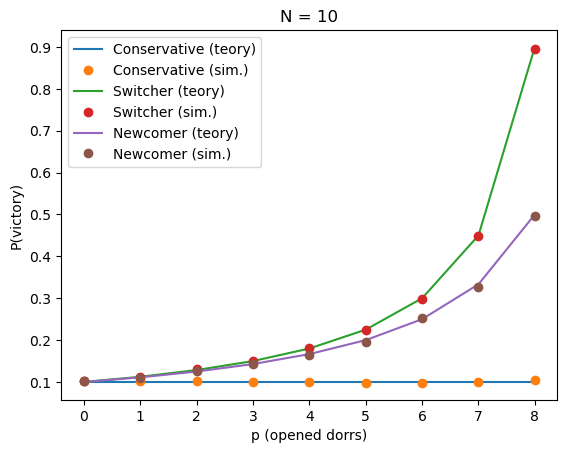

In [37]:
N = 10
ps = np.arange(0, N - 1)          # p = 0 ... N-2
sim = np.array([simulate(N, p) for p in ps])
th = np.array([theory(N, p) for p in ps])

labels = ["Conservative", "Switcher", "Newcomer"]
for i, lab in enumerate(labels):
    plt.plot(ps, th[:, i], "-", label=f"{lab} (teory)")
    plt.plot(ps, sim[:, i], "o", label=f"{lab} (sim.)")
plt.xlabel("p (opened dorrs)")
plt.ylabel("P(victory)")
plt.title(f"N = {N}")
plt.legend()
plt.show()